# Giai đoạn 3 – Pipeline tiền xử lý thống nhất

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/23010216-hieusphamj/text-summarization-nlp/blob/main/notebooks/03_preprocessing.ipynb)

**Mục tiêu**
1. Làm sạch CNN/DM (bỏ tiền tố rác `By . ... PUBLISHED:`, dateline `(CNN) --`...) và thống nhất định dạng với GOV.UK.
2. Lọc ngoại lệ **chỉ ở tập train** CNN/DM; kiểm tra rò rỉ giữa train và val/test.
3. **Đo bằng tokenizer thật** (BART, T5) tỉ lệ bài bị cắt ở 512 / 1024 token và tóm tắt bị cắt ở 64 / 128 token → chốt `max_input`, `max_target` bằng số liệu.
4. Dựng `Dataset` + `DataCollator` và in shape tensor (luồng dữ liệu cho báo cáo).

> Chạy từ trên xuống. Sau khi kernel khởi động lại, **luôn chạy lại cell 0 và cell 1** trước. Không cần GPU.

In [1]:
# 0. Thiết lập môi trường
import os, sys, subprocess
from pathlib import Path

REPO_URL = "https://github.com/23010216-hieusphamj/text-summarization-nlp.git"
IN_COLAB = "google.colab" in sys.modules

if IN_COLAB and not Path("src").exists() and not Path("text-summarization-nlp").exists():
    subprocess.run(["git", "clone", REPO_URL], check=True)
if Path("text-summarization-nlp").exists():
    os.chdir("text-summarization-nlp")
while not Path("src").exists() and Path.cwd() != Path.cwd().parent:
    os.chdir("..")
sys.path.insert(0, os.getcwd())

DRIVE = None
if IN_COLAB:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r", "requirements-colab.txt"], check=True)
    from google.colab import drive
    drive.mount("/content/drive")
    DRIVE = Path("/content/drive/MyDrive/nlp_summarization"); DRIVE.mkdir(parents=True, exist_ok=True)
print("Thư mục làm việc:", os.getcwd())

Mounted at /content/drive
Thư mục làm việc: /content/text-summarization-nlp


## 1. Chuẩn bị đầu vào (kết quả GĐ1 và GĐ2)
Các file `data/processed/*.jsonl` không nằm trên GitHub. Cell này khôi phục từ Drive nếu có, nếu không thì dựng lại (CNN/DM tải lại từ HuggingFace, GOV.UK dựng từ cache thô trên Drive) rồi lưu bản sao lên Drive cho các giai đoạn sau.

In [2]:
import shutil, time
PROC = Path("data/processed"); PROC.mkdir(parents=True, exist_ok=True)
NEED = [f"{s}_{sp}.jsonl" for s in ("cnn_dm", "govuk") for sp in ("train", "validation", "test")]
missing = lambda: [f for f in NEED if not (PROC / f).exists()]

if missing() and DRIVE and (DRIVE / "processed").exists():
    for f in NEED:
        if (DRIVE / "processed" / f).exists():
            shutil.copy(DRIVE / "processed" / f, PROC / f)
    print("Đã khôi phục từ Drive; còn thiếu:", missing())

if any(f.startswith("cnn_dm") for f in missing()):
    from src.data.cnn_dm import main as build_cnn
    build_cnn("configs/data_cnn_dm.yaml")

if any(f.startswith("govuk") for f in missing()):
    raw = Path("data/raw/govuk"); raw.mkdir(parents=True, exist_ok=True)
    if not any(raw.glob("*.json")):
        drive_raw = DRIVE / "govuk_raw"
        assert drive_raw.exists(), "Không có cache thô GOV.UK trên Drive; hãy chạy notebook 02 trước."
        t0 = time.time()
        subprocess.run(f"cd {drive_raw} && ls | xargs -P 16 -I{{}} cp {{}} {raw.resolve()}/", shell=True, check=True)
        print(f"Đã chép {len(list(raw.glob('*.json')))} file cache ({time.time() - t0:.0f}s)")
    from src.crawl.build_dataset import main as build_gov
    build_gov("configs/data_govuk.yaml")

assert not missing(), missing()
if DRIVE:
    (DRIVE / "processed").mkdir(exist_ok=True)
    for f in NEED:
        shutil.copy(PROC / f, DRIVE / "processed" / f)
print("Sẵn sàng:", {f: sum(1 for _ in open(PROC / f, encoding="utf-8")) for f in NEED})

Đã khôi phục từ Drive; còn thiếu: []
Sẵn sàng: {'cnn_dm_train.jsonl': 20000, 'cnn_dm_validation.jsonl': 1000, 'cnn_dm_test.jsonl': 1000, 'govuk_train.jsonl': 3102, 'govuk_validation.jsonl': 387, 'govuk_test.jsonl': 389}


## 2. Làm sạch và lọc
Làm sạch áp dụng cho mọi tập. Lọc ngoại lệ (bài quá ngắn, tóm tắt quá ngắn/dài) **chỉ áp dụng cho train CNN/DM**, để val/test giữ nguyên phân bố thật khi so sánh với các công trình khác.

In [3]:
import yaml, pandas as pd, numpy as np, matplotlib.pyplot as plt
from src.preprocessing.build_clean import main as run_clean, read_jsonl

CFG_PATH = "configs/preprocess.yaml"
cfg = yaml.safe_load(open(CFG_PATH, encoding="utf-8"))
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})
FIG = Path(cfg["figures_dir"]); FIG.mkdir(parents=True, exist_ok=True)
TAB = Path(cfg["tables_dir"]);  TAB.mkdir(parents=True, exist_ok=True)

summary = run_clean(CFG_PATH)

source      split  n_input  n_changed_by_cleaning  n_removed_by_filter  n_output
cnn_dm      train    20000                  14084                  105     19895
cnn_dm validation     1000                    333                    0      1000
cnn_dm       test     1000                    356                    0      1000
 govuk      train     3102                      2                    0      3102
 govuk validation      387                      1                    0       387
 govuk       test      389                      0                    0       389
source      split  articles_also_in_train
cnn_dm validation                       0
cnn_dm       test                       0
 govuk validation                       1
 govuk       test                       0


### 2.1 Kiểm tra trước/sau khi làm sạch (CNN/DM, cả train, validation và test)

In [4]:
import re
# Kiểm tra độc lập với các regex làm sạch: còn dấu vết ở 120 ký tự đầu không?
HEAD = {"By . (đầu bài)": r"^\s*By\s*\.", "PUBLISHED/UPDATED": r"PUBLISHED\s*:|UPDATED\s*:|Last updated at",
        "(CNN) ở đầu bài": r"\(CNN\)", "Scroll down for video": r"(?i)scroll down for"}
ANY = r"PUBLISHED\s*:|UPDATED\s*:|^\s*By\s*\.|\(CNN\)"
rows, left, changed_pct = [], {}, {}
for split in ["train", "validation", "test"]:
    raw_s = read_jsonl(Path(cfg["input_dir"]) / f"cnn_dm_{split}.jsonl")
    cln_s = {r["id"]: r for r in read_jsonl(Path(cfg["output_dir"]) / f"cnn_dm_{split}.jsonl")}
    pairs_s = [(r["article"], cln_s[r["id"]]["article"]) for r in raw_s if r["id"] in cln_s]
    if split == "train":
        pairs = pairs_s                      # dùng cho cell xem ví dụ bên dưới
    for name, pat in HEAD.items():
        rows.append({"split": split, "dấu vết": name,
                     "% trước": round(np.mean([bool(re.search(pat, a[:120])) for a, _ in pairs_s]) * 100, 2),
                     "% sau": round(np.mean([bool(re.search(pat, b[:120])) for _, b in pairs_s]) * 100, 2)})
    changed_pct[split] = np.mean([re.sub(r"\s+", " ", a).strip() != b for a, b in pairs_s]) * 100
    left[split] = [b[:160] for _, b in pairs_s if re.search(ANY, b[:120])]
chk = pd.DataFrame(rows); chk.to_csv(TAB / "cleaning_residual_check.csv", index=False)
print("Tỉ lệ bài bị thay đổi nội dung (ngoài khoảng trắng):", {k: f"{v:.1f}%" for k, v in changed_pct.items()})
print("Số bài còn sót dấu vết:", {k: len(v) for k, v in left.items()})
chk.pivot(index="dấu vết", columns="split", values=["% trước", "% sau"])

Tỉ lệ bài bị thay đổi nội dung (ngoài khoảng trắng): {'train': '70.4%', 'validation': '33.3%', 'test': '35.6%'}
Số bài còn sót dấu vết: {'train': 33, 'validation': 0, 'test': 0}


% trước                   % sau                 
split                    test  train validation  test train validation
dấu vết                                                               
(CNN) ở đầu bài           8.4  25.89        7.8   0.0  0.03        0.0
By . (đầu bài)            0.0  34.16        0.0   0.0  0.02        0.0
PUBLISHED/UPDATED         0.0  21.96        0.0   0.0  0.14        0.0
Scroll down for video     0.0   0.03        0.0   0.0  0.00        0.0

In [5]:
# Xem ngẫu nhiên 6 mẫu (150 ký tự đầu) trước và sau, và các bài còn sót (nếu có)
rng = np.random.default_rng(1)
ex = []
for i in rng.choice(len(pairs), 6, replace=False):
    a, b = pairs[i]
    print("TRƯỚC:", repr(a[:150])); print("SAU  :", repr(b[:150])); print()
    ex.append({"truoc_150": a[:150], "sau_150": b[:150]})
pd.DataFrame(ex).to_csv(TAB / "cleaning_examples.csv", index=False)
for split, items in left.items():
    print(f"== {split}: còn sót {len(items)}")
    for x in items[:8]: print("  ", repr(x))

TRƯỚC: 'James Rodriguez (42%) Stephanie Roche (33%) Robin van Persie (11%) There was no fairytale ending to Stephanie Roche’s remarkable journey and there was'
SAU  : 'James Rodriguez (42%) Stephanie Roche (33%) Robin van Persie (11%) There was no fairytale ending to Stephanie Roche’s remarkable journey and there was'

TRƯỚC: 'Kimi Raikkonen sustained an incredible 47G impact during his opening-lap shunt at the British Grand Prix. The Finn was immediately taken to the on-tra'
SAU  : 'Kimi Raikkonen sustained an incredible 47G impact during his opening-lap shunt at the British Grand Prix. The Finn was immediately taken to the on-tra'

TRƯỚC: 'By . Claire Bates . UPDATED: . 10:51 EST, 2 January 2012 . A little girl who has spent her entire life crippled by cerebral palsy has\xa0 taken her first'
SAU  : 'A little girl who has spent her entire life crippled by cerebral palsy has taken her first steps. Since undergoing pioneering surgery in the U.S. Lily'

TRƯỚC: 'The investigation into the

### 2.2 Lọc train, kiểm tra rò rỉ

In [6]:
display(summary)
display(pd.read_csv(TAB / "leakage_check.csv"))

,source,split,n_input,n_changed_by_cleaning,n_removed_by_filter,n_output
0,cnn_dm,train,20000,14084,105,19895
1,cnn_dm,validation,1000,333,0,1000
2,cnn_dm,test,1000,356,0,1000
3,govuk,train,3102,2,0,3102
4,govuk,validation,387,1,0,387
5,govuk,test,389,0,0,389


,source,split,articles_also_in_train
0,cnn_dm,validation,0
1,cnn_dm,test,0
2,govuk,validation,1
3,govuk,test,0


## 3. Đo độ dài token bằng tokenizer thật
Quyết định `max_input` / `max_target` phải dựa trên số liệu: bao nhiêu % bài bị cắt và bao nhiêu % token bị mất.
Với T5, đầu vào có thêm tiền tố `summarize: `.

In [7]:
from transformers import AutoTokenizer
from src.preprocessing.tokenization import token_lengths, truncation_report

toks = {k: AutoTokenizer.from_pretrained(v) for k, v in cfg["tokenizers"].items()}
clean = {s: read_jsonl(Path(cfg["output_dir"]) / f"{s}_train.jsonl") for s in cfg["sources"]}
print({s: len(v) for s, v in clean.items()})

config.json:   0%|          | 0.00/1.72k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/899k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

config.json:   0%|          | 0.00/1.21k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/2.32k [00:00<?, ?B/s]

spiece.model:   0%|          | 0.00/792k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.39M [00:00<?, ?B/s]

{'cnn_dm': 19895, 'govuk': 3102}


In [8]:
rows, L = [], {}
for source, recs in clean.items():
    arts = [r["article"] for r in recs]
    sums = [r["highlights"].replace("\n", cfg["target_join"]) for r in recs]
    for tname, tok in toks.items():
        prefix = cfg["t5_prefix"] if tname == "t5" else ""
        L[(source, tname, "input")]  = token_lengths([prefix + a for a in arts], tok)
        L[(source, tname, "target")] = token_lengths(sums, tok)

for (source, tname, field), lens in L.items():
    thr = cfg["max_input_candidates"] if field == "input" else cfg["max_target_candidates"][source]
    pct = {p: int(np.percentile(lens, p)) for p in (50, 95, 99)}
    for r in truncation_report(lens, thr):
        rows.append({"source": source, "tokenizer": tname, "field": field, "p50": pct[50], "p95": pct[95], "p99": pct[99], **{k: round(v, 1) for k, v in r.items()}})
trunc = pd.DataFrame(rows)
trunc.to_csv(TAB / "token_truncation_report.csv", index=False)
trunc

,source,tokenizer,field,p50,p95,p99,max_len,pct_truncated,pct_tokens_lost
0,cnn_dm,bart,input,788,1690,2104,512,79.0,43.7
1,cnn_dm,bart,input,788,1690,2104,1024,29.1,12.4
2,cnn_dm,bart,target,60,109,140,128,2.0,0.5
3,cnn_dm,t5,input,889,1922,2393,512,84.8,49.4
4,cnn_dm,t5,input,889,1922,2393,1024,38.4,17.1
5,cnn_dm,t5,target,70,128,165,128,4.9,1.5
6,govuk,bart,input,673,1737,2405,512,64.3,43.1
7,govuk,bart,input,673,1737,2405,1024,26.3,14.4
8,govuk,bart,target,27,44,58,64,0.7,0.2
9,govuk,bart,target,27,44,58,128,0.0,0.0


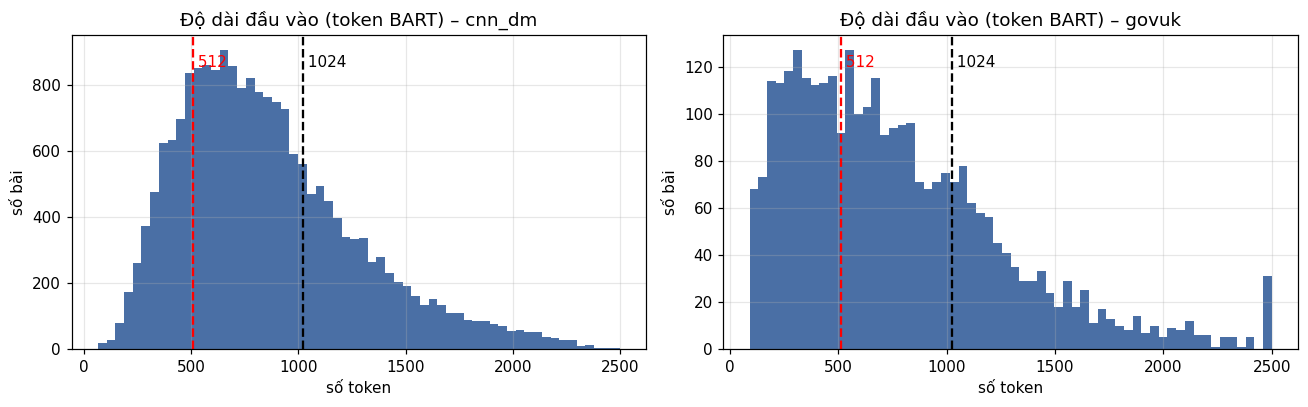

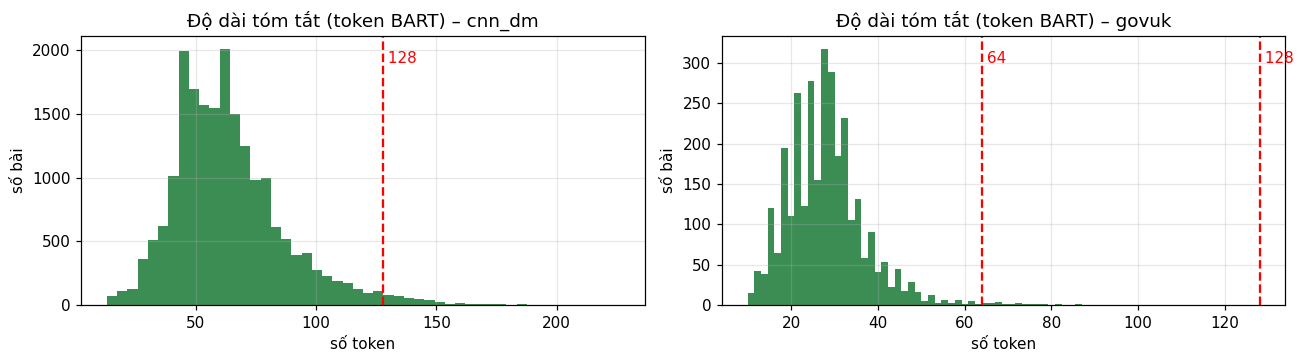

In [9]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
for a, source in zip(ax, ["cnn_dm", "govuk"]):
    lens = L[(source, "bart", "input")]
    a.hist(np.clip(lens, 0, 2500), bins=60, color="#4a6fa5")
    for t, c in zip(cfg["max_input_candidates"], ["r", "k"]):
        a.axvline(t, ls="--", c=c); a.text(t, a.get_ylim()[1] * 0.9, f" {t}", color=c)
    a.set_title(f"Độ dài đầu vào (token BART) – {source}"); a.set_xlabel("số token"); a.set_ylabel("số bài")
plt.tight_layout(); plt.savefig(FIG / "token_length_input.png", dpi=200); plt.show()

fig, ax = plt.subplots(1, 2, figsize=(12, 3.4))
for a, source in zip(ax, ["cnn_dm", "govuk"]):
    lens = L[(source, "bart", "target")]
    a.hist(np.clip(lens, 0, 250), bins=50, color="#3c8d53")
    for t in cfg["max_target_candidates"][source]:
        a.axvline(t, ls="--", c="r"); a.text(t, a.get_ylim()[1] * 0.9, f" {t}", color="r")
    a.set_title(f"Độ dài tóm tắt (token BART) – {source}"); a.set_xlabel("số token"); a.set_ylabel("số bài")
plt.tight_layout(); plt.savefig(FIG / "token_length_target.png", dpi=200); plt.show()

## 4. Luồng dữ liệu: Dataset → DataCollator → batch (shape tensor)

In [10]:
from transformers import DataCollatorForSeq2Seq
from torch.utils.data import DataLoader
from src.preprocessing.tokenization import build_tokenized_dataset

MAX_IN, MAX_OUT = 512, 128
tok = toks["bart"]
ds = build_tokenized_dataset(clean["cnn_dm"][:200], tok, MAX_IN, MAX_OUT)
coll = DataCollatorForSeq2Seq(tok, label_pad_token_id=-100, return_tensors="pt")
batch = next(iter(DataLoader(ds, batch_size=4, collate_fn=coll)))
for k, v in batch.items():
    print(f"{k:<16} shape={tuple(v.shape)} dtype={v.dtype}")
print("\nĐầu vào (giải mã, 200 ký tự):", tok.decode(batch["input_ids"][0])[:200])
lab = batch["labels"][0]; lab = lab[lab != -100]
print("Nhãn (giải mã):", tok.decode(lab))

Map:   0%|          | 0/200 [00:00<?, ? examples/s]

input_ids        shape=(4, 512) dtype=torch.int64
attention_mask   shape=(4, 512) dtype=torch.int64
labels           shape=(4, 62) dtype=torch.int64

Đầu vào (giải mã, 200 ký tự): <s>Three members of the same family who died in a static caravan from carbon monoxide poisoning would have been unconscious 'within minutes', investigators said today. The bodies of married couple Joh
Nhãn (giải mã): <s>John and . Audrey Cook were discovered alongside their daughter, Maureen . They were found at Tremarle Home Park in Cornwall . Investigators say the three died of carbon monoxide . poisoning .</s>


## 5. Nhận xét (điền sau khi chạy, rồi chép vào `docs/decisions.md` mục D7 và cập nhật D2)

- **Làm sạch CNN/DM:** bỏ tiền tố Daily Mail (byline, PUBLISHED/UPDATED), dateline CNN (kể cả địa danh viết hoa/thường và kiểu "(CNN)Nội dung" không có dấu "--"), cụm rác giữa bài (Scroll down for video, E-mail to a friend, Share this article) và URL; chuẩn hóa khoảng trắng. Nội dung bị thay đổi ở 14.084/20.000 bài train (70,4%), 333/1.000 val (33,3%) và 356/1.000 test (35,6%).
- **Kết quả kiểm tra (120 ký tự đầu, train):** "By ." giảm từ 34,16% xuống 0,02%; PUBLISHED/UPDATED từ 21,96% xuống 0,14%; "(CNN)" từ 25,89% xuống 0,03%. Còn sót 33/19.895 bài train (0,17%), 0 bài ở val và test. Quy tắc làm sạch được hiệu chỉnh hai vòng sau khi kiểm tra các bài còn sót (vòng 1 còn sót 8,5% ở train do dateline viết thường và byline có từ nối).
- **Khác biệt định dạng giữa các tập:** trước khi làm sạch, val/test không có tiền tố Daily Mail (0%) nhưng train có "By ." ở 34,16% và PUBLISHED/UPDATED ở 21,96%. Nếu không làm sạch, mô hình sẽ học các tiền tố không bao giờ xuất hiện ở tập test.
- **Lọc ngoại lệ:** chỉ ở train CNN/DM (bài < 50 từ, tóm tắt < 10 hoặc > 150 từ, > 10 câu): loại 105/20.000 bài (0,5%), còn 19.895. Val (1.000) và test (1.000) giữ nguyên để so sánh công bằng với công trình khác. GOV.UK đã lọc ở GĐ2, chỉ thống nhất khoảng trắng (3.102 / 387 / 389).
- **Rò rỉ dữ liệu** (trùng 300 ký tự đầu đã chuẩn hóa với train, tính sau làm sạch): CNN/DM validation 0, test 0; GOV.UK validation 1/387 (0,26%), test 0. Bài GOV.UK trùng ở validation được giữ lại vì tập này chỉ dùng chọn mô hình và tác động không đáng kể.
- **Đầu vào mô hình:** BART nhận văn bản thuần, T5 thêm tiền tố "summarize: "; tóm tắt nhiều câu nối bằng khoảng trắng khi huấn luyện, giữ xuống dòng để tính ROUGE-Lsum; đệm động (DataCollatorForSeq2Seq, nhãn đệm -100).
- **Độ dài (đo bằng tokenizer thật, train, sau làm sạch):**
  - CNN/DM (BART): trung vị 788, p95 1.690, p99 2.104 token. Ở 512 token: 79,0% bài bị cắt, mất 43,7% token; ở 1.024 token: 29,1% bị cắt, mất 12,4%. T5 (có tiền tố) cắt nhiều hơn: 84,8% (mất 49,4%) ở 512 và 38,4% (mất 17,1%) ở 1.024.
  - GOV.UK (BART): trung vị 673, p95 1.737 token; ở 512 token: 64,3% bị cắt, mất 43,1% token; ở 1.024 token: 26,3%, mất 14,4%.
  - Tóm tắt: CNN/DM trung vị 60, p95 109 token; 2,0% dài hơn 128 token (BART; T5: 4,9%), mất 0,5% token. GOV.UK trung vị 27, p95 44 token; 0,7% dài hơn 64 token (BART), 0% dài hơn 128.
  - **Quyết định:** `max_input = 512` làm cấu hình mặc định cho mọi mô hình (huấn luyện nhanh, vừa GPU T4, công bằng khi so sánh); `max_target = 128` (CNN/DM) và `64` (GOV.UK). BART-base chạy thêm `max_input = 1024` như ablation ở GĐ6.
- **Đánh đổi:** cắt ở 512 token làm mất thông tin cuối bài (79% bài CNN/DM bị cắt). Với CNN/DM, 64% câu tóm tắt có nguồn nằm trong 10 câu đầu nên việc cắt chấp nhận được nhưng không miễn phí; ablation 512 vs 1024 ở GĐ6 sẽ đo tác động thực tế lên ROUGE. Các regex làm sạch được thiết kế theo định dạng của CNN/DM nên không dùng được nguyên cho nguồn khác.

In [11]:
# 6. Lưu bản sao đã làm sạch lên Drive; (Colab) đóng gói kết quả để tải về
if DRIVE:
    (DRIVE / "clean").mkdir(exist_ok=True)
    for f in Path(cfg["output_dir"]).glob("*.jsonl"):
        shutil.copy(f, DRIVE / "clean" / f.name)
    print("Đã lưu dữ liệu sạch lên", DRIVE / "clean")
if IN_COLAB:
    from google.colab import files
    shutil.make_archive("phase3_outputs", "zip", ".", "results")
    files.download("phase3_outputs.zip")

Đã lưu dữ liệu sạch lên /content/drive/MyDrive/nlp_summarization/clean


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>